In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as sp

In [2]:
num_cc = []
xx = []
for i in range(1000):
    df = pd.read_json(
        f"../data/processed/2021/bs_500_random/random_{i:03}/metrics_growth.json"
    )
    num_cc.append(df["num_cc"].values)
    xx.append(df["xx"].values)

In [3]:
num_cc = np.mean(np.transpose(num_cc), axis=1)
xx = np.mean(np.transpose(xx), axis=1)

In [4]:
num_cc_real = []
xx_real = []
for i in range(1000):
    df = pd.read_json(
        f"../data/processed/2021/bs_500_real_random/real_random_{i:03}/metrics_growth.json"
    )
    num_cc_real.append(df["num_cc"].values)
    xx_real.append(df["xx"].values)

In [5]:
num_cc_real = np.mean(np.transpose(num_cc_real), axis=1)
xx_real = np.mean(np.transpose(xx_real), axis=1)

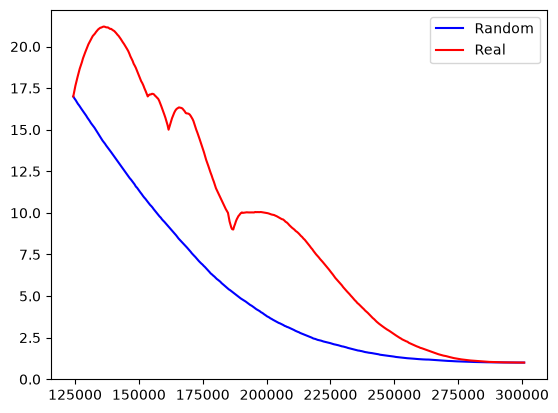

In [6]:
fig, ax = plt.subplots()
ax.plot(xx, num_cc, color="blue", label="Random")
ax.plot(xx_real, num_cc_real, color="red", label="Real")
ax.legend()

In [7]:
auc = pd.read_json("../data/processed/2021/auc_table_growth_bs_500.json")

In [8]:
mean_rand_cov = auc[auc["Metric optimized"] == "random"]["AUC of Coverage"].mean()

In [9]:
std_rand_cov = auc[auc["Metric optimized"] == "random"]["AUC of Coverage"].std()

In [10]:
mean_rand_dir = auc[auc["Metric optimized"] == "random"]["AUC of Directness"].mean()

In [11]:
std_rand_dir = auc[auc["Metric optimized"] == "random"]["AUC of Directness"].std()

In [12]:
real_cov = auc[auc["Metric optimized"] == "real_random"]["AUC of Coverage"].values[0]

In [13]:
real_dir = auc[auc["Metric optimized"] == "real_random"]["AUC of Directness"].values[0]

In [14]:
np.abs((real_cov - mean_rand_cov) / std_rand_cov)

np.float64(2.720296659441332)

In [15]:
np.abs((real_dir - mean_rand_dir) / std_rand_dir)

np.float64(0.8436886513813733)

(array([  2.,   2.,   2.,   4.,  18.,  24.,  56.,  70.,  92.,  96., 116.,
        112., 136., 103.,  60.,  51.,  29.,  14.,  12.,   1.]),
 array([0.59931447, 0.60988996, 0.62046546, 0.63104095, 0.64161644,
        0.65219194, 0.66276743, 0.67334293, 0.68391842, 0.69449392,
        0.70506941, 0.7156449 , 0.7262204 , 0.73679589, 0.74737139,
        0.75794688, 0.76852238, 0.77909787, 0.78967336, 0.80024886,
        0.81082435]),
 <BarContainer object of 20 artists>)

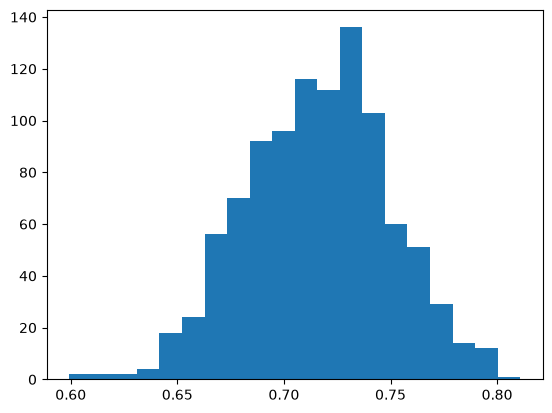

In [16]:
plt.hist(auc[auc["Metric optimized"] == "random"]["AUC of Coverage"].values, bins=20)

(array([  3.,   5.,   8.,   8.,  21.,  41.,  56.,  78., 108., 112., 116.,
        120., 102.,  86.,  65.,  26.,  25.,  13.,   5.,   2.]),
 array([0.58770411, 0.59234885, 0.59699359, 0.60163833, 0.60628307,
        0.6109278 , 0.61557254, 0.62021728, 0.62486202, 0.62950676,
        0.63415149, 0.63879623, 0.64344097, 0.64808571, 0.65273045,
        0.65737518, 0.66201992, 0.66666466, 0.6713094 , 0.67595414,
        0.68059887]),
 <BarContainer object of 20 artists>)

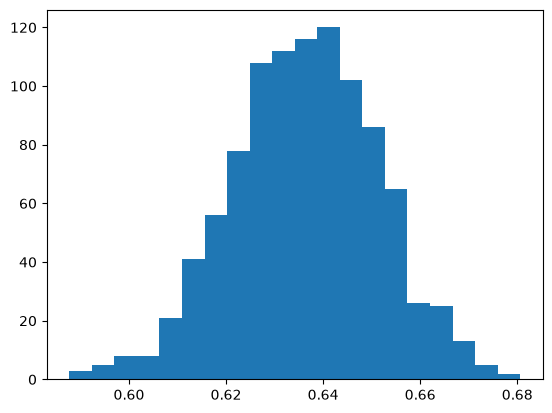

In [17]:
plt.hist(auc[auc["Metric optimized"] == "random"]["AUC of Directness"].values, bins=20)

In [18]:
sp.normaltest(auc[auc["Metric optimized"] == "random"]["AUC of Coverage"].values)

NormaltestResult(statistic=np.float64(2.193700341039878), pvalue=np.float64(0.3339212238635569))

In [19]:
sp.normaltest(auc[auc["Metric optimized"] == "random"]["AUC of Directness"].values)

NormaltestResult(statistic=np.float64(3.6147685249507173), pvalue=np.float64(0.16408277342545372))

In [20]:
sp.kstest(
    (
        auc[auc["Metric optimized"] == "random"]["AUC of Directness"].values
        - mean_rand_dir
    )
    / std_rand_dir,
    "norm",
)

KstestResult(statistic=np.float64(0.017865878808804525), pvalue=np.float64(0.9011987473606948), statistic_location=np.float64(0.23750087253140323), statistic_sign=np.int8(-1))

In [21]:
sp.kstest(
    (auc[auc["Metric optimized"] == "random"]["AUC of Coverage"].values - mean_rand_cov)
    / std_rand_cov,
    "norm",
)

KstestResult(statistic=np.float64(0.031184740466106864), pvalue=np.float64(0.27933346353641353), statistic_location=np.float64(0.27198894574523036), statistic_sign=np.int8(-1))

In [22]:
sp.shapiro(auc[auc["Metric optimized"] == "random"]["AUC of Directness"].values)

ShapiroResult(statistic=np.float64(0.9980910042561076), pvalue=np.float64(0.3228615467995168))

In [23]:
sp.shapiro(auc[auc["Metric optimized"] == "random"]["AUC of Coverage"].values)

ShapiroResult(statistic=np.float64(0.997758312628835), pvalue=np.float64(0.1955698730380253))

In [24]:
sp.ttest_ind(
    real_cov, auc[auc["Metric optimized"] == "random"]["AUC of Coverage"].values
)

TtestResult(statistic=np.float64(2.7189375303735095), pvalue=np.float64(0.006662704452051795), df=np.float64(999.0))

In [25]:
sp.ttest_ind(
    real_dir, auc[auc["Metric optimized"] == "random"]["AUC of Directness"].values
)

TtestResult(statistic=np.float64(-0.8432671231755047), pvalue=np.float64(0.39928092370403057), df=np.float64(999.0))

In [26]:
sp.ttest_ind(
    [real_cov, real_dir],
    auc[auc["Metric optimized"] == "random"][
        ["AUC of Coverage", "AUC of Directness"]
    ].values,
)

TtestResult(statistic=array([ 2.71893753, -0.84326712]), pvalue=array([0.0066627 , 0.39928092]), df=array([999., 999.]))